<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/statistics/BrownianMotion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

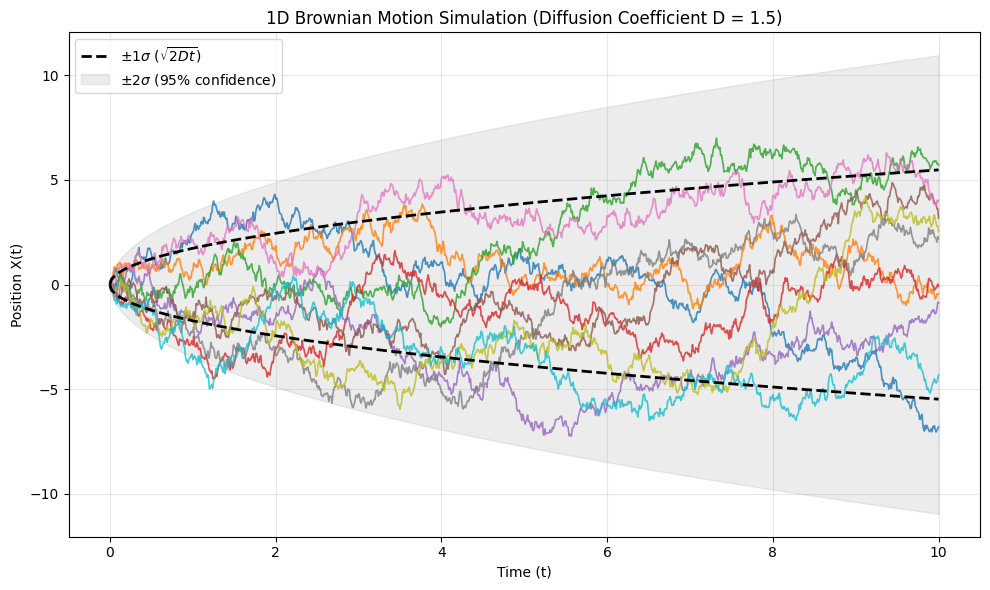

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_brownian_motion(D: float, T: float, dt: float, num_paths: int = 5):
    """
    Simulates 1D Brownian motion as a cumulative sum of normal random variables.

    Parameters:
    D (float): Diffusion coefficient (units: length^2 / time)
    T (float): Total simulation time
    dt (float): Time step size
    num_paths (int): Number of independent trajectories to simulate
    """
    # Number of time steps
    N = int(T / dt)
    t = np.linspace(0, T, N + 1)

    # Standard deviation of each step: sigma = sqrt(2 * D * dt)
    # Note: In financial math (standard Wiener process), variance is simply dt (so D = 0.5)
    step_std = np.sqrt(2 * D * dt)

    # Generate random increments: shape (num_paths, N)
    # Each increment is drawn from N(0, 2 * D * dt)
    increments = np.random.normal(loc=0.0, scale=step_std, size=(num_paths, N))

    # Prepend zeros so all paths start at X(0) = 0
    X = np.zeros((num_paths, N + 1))
    X[:, 1:] = np.cumsum(increments, axis=1)

    return t, X

# --- Parameters ---
D = 1.5          # Diffusion coefficient
T = 10.0         # Total time (seconds)
dt = 0.01        # Time step (seconds)
num_paths = 10   # Number of particles/paths

# Run simulation
t, trajectories = simulate_brownian_motion(D, T, dt, num_paths)

# --- Plotting ---
plt.figure(figsize=(10, 6))

# Plot each simulated path
for i in range(num_paths):
    plt.plot(t, trajectories[i], lw=1.2, alpha=0.8)

# Plot theoretical +/- 1 and 2 standard deviation envelopes: std(t) = sqrt(2 * D * t)
theoretical_std = np.sqrt(2 * D * t)
plt.plot(t, theoretical_std, 'k--', lw=2, label=r'$\pm 1\sigma$ ($\sqrt{2Dt}$)')
plt.plot(t, -theoretical_std, 'k--', lw=2)
plt.fill_between(t, -2 * theoretical_std, 2 * theoretical_std, color='gray', alpha=0.15, label=r'$\pm 2\sigma$ (95% confidence)')

plt.title(f"1D Brownian Motion Simulation (Diffusion Coefficient D = {D})")
plt.xlabel("Time (t)")
plt.ylabel("Position X(t)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()